# 矩阵计算器 · 线性代数演示 Notebook

这个 Notebook 展示如何把命令行计算器背后的**计算核心**当作函数库使用，
并用图把几个抽象概念“画出来”。

- 计算核心：`matrix_calculator`（NumPy）
- 可视化：`matrix_calculator.visualization`（matplotlib）

> 提示：逐格运行：点击单元格后按 `Shift + Enter`；也可以在菜单选
> `Run All` 一次运行全部。

In [1]:
# 环境准备：把 src/ 加入导入路径
# 如果你已经执行过 `pip install -e .`，这一格也不会有副作用。
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
print("项目根目录：", project_root)

项目根目录： H:\Project\Max_calc\.worktrees\notebook-demo


## 1. 基础矩阵运算

直接调用纯函数，不需要启动命令行菜单。

In [2]:
import numpy as np
from matrix_calculator import (
    add_matrices,
    matrix_multiply,
    determinant,
    invert_matrix,
    format_matrix,
)

A = np.array([[1.0, 2.0],
              [3.0, 4.0]])
B = np.array([[5.0, 6.0],
              [7.0, 8.0]])

print("A + B =")
print(format_matrix(add_matrices(A, B)))
print()
print("A × B =")
print(format_matrix(matrix_multiply(A, B)))
print()
print("det(A) =", determinant(A))
print("A 的逆矩阵 =")
print(format_matrix(invert_matrix(A)))

A + B =
⎡  6   8 ⎤
⎣ 10  12 ⎦

A × B =
⎡ 19  22 ⎤
⎣ 43  50 ⎦

det(A) = -2.0000000000000004
A 的逆矩阵 =
⎡  -2     1 ⎤
⎣ 1.5  -0.5 ⎦


In [3]:
# 参数不合法时，核心函数会抛出明确的异常，而不是打印后返回 None
from matrix_calculator import MatrixOperationError

try:
    add_matrices(np.zeros((2, 2)), np.zeros((2, 3)))
except MatrixOperationError as e:
    print("捕获到错误：", e)

捕获到错误： 两个待相加矩阵的 shape 不一致，无法操作


## 2. 解线性方程组 Ax = b

`solve_linear` 会根据秩判定三种情况：唯一解、无穷多解、无解。

In [4]:
from matrix_calculator import solve_linear

# 唯一解：2x1=4, 3x2=9
A1 = np.array([[2.0, 0.0],
               [0.0, 3.0]])
b1 = np.array([4.0, 9.0])

status, info = solve_linear(A1, b1)
print("状态：", status)
print("秩 r(A) =", info["rA"], "，r(A|b) =", info["rAb"], "，n =", info["n"])
print("唯一解 x =", info["x"])

状态： unique
秩 r(A) = 2 ，r(A|b) = 2 ，n = 2
唯一解 x = [2. 3.]


In [5]:
# 无穷多解：第二行方程是第一行的 2 倍
A2 = np.array([[1.0, 1.0],
               [2.0, 2.0]])
b2 = np.array([1.0, 2.0])

status, info = solve_linear(A2, b2)
print("状态：", status)
print("一个特解 xp =", info["xp"])
print("基础解系（每列一个向量 ξ）：")
print(format_matrix(info["null"]))
print("通解是一条直线：x = xp + c·ξ，c 为任意常数")

状态： infinite
一个特解 xp = [0.5 0.5]
基础解系（每列一个向量 ξ）：
⎡ -0.7071 ⎤
⎣  0.7071 ⎦
通解是一条直线：x = xp + c·ξ，c 为任意常数


## 3. 二维线性变换可视化

矩阵 `A` 可以理解为对平面向量的“变形规则”：蓝色是原始向量，
红色是经过 `A` 作用后的向量。观察拉伸、剪切的方向。

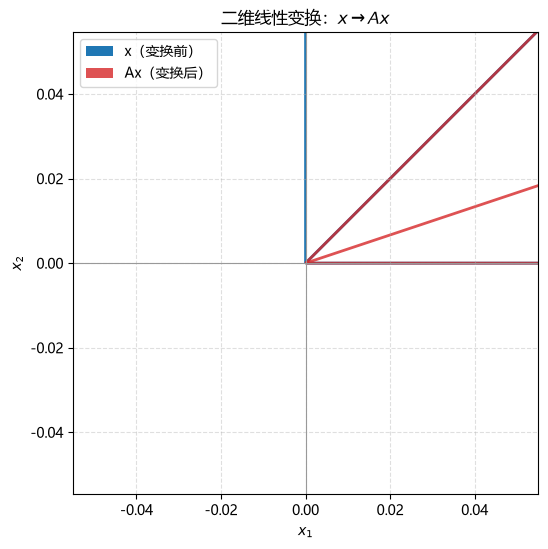

特征值： [2.+0.j 1.+0.j]
特征向量（每一列对应一个特征值）：
⎡ 1  -0.7071 ⎤
⎣ 0   0.7071 ⎦


In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
from matrix_calculator.visualization import plot_linear_transform

# 剪切 + 拉伸变换
A_transform = np.array([[2.0, 1.0],
                        [0.0, 1.0]])

fig, ax = plt.subplots(figsize=(6, 6))
plot_linear_transform(A_transform, ax=ax)
plt.show()

# 顺便看一下它的特征值（沿哪个方向只被拉伸、不被改变方向）
eigvals, eigvecs = np.linalg.eig(A_transform)
print("特征值：", eigvals)
print("特征向量（每一列对应一个特征值）：")
print(format_matrix(eigvecs))

## 4. SVD 奇异值图

奇异值衡量矩阵在各个方向上的“作用强度”。在数据分析里，
PCA、降维、数据压缩都会观察类似的衰减图：大的奇异值代表主要信息，
接近 0 的奇异值代表冗余或噪声方向。

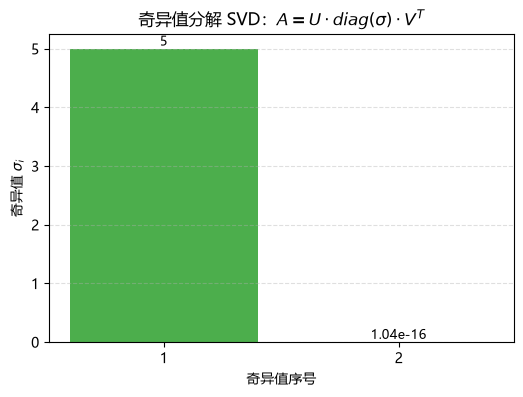

奇异值： [5.00000000e+00 1.04061363e-16]
非零奇异值的个数 = 矩阵的秩 = 1


In [7]:
from matrix_calculator.visualization import plot_singular_values

# 一个秩亏（rank-deficient）矩阵：第二行是第一行的 2 倍 → 有一个奇异值为 0
A_rank = np.array([[1.0, 2.0],
                   [2.0, 4.0]])

fig, ax = plt.subplots(figsize=(6, 4))
_, s = plot_singular_values(A_rank, ax=ax)
plt.show()

print("奇异值：", s)
print("非零奇异值的个数 = 矩阵的秩 =", int(np.sum(s > 1e-9)))

In [8]:
# 验证 SVD 可以完整还原原矩阵：A = U · diag(S) · Vt
U, S, Vt = np.linalg.svd(A_rank)
A_reconstructed = U @ np.diag(S) @ Vt
print("U·diag(S)·Vt 与 A 的最大误差：", np.max(np.abs(A_reconstructed - A_rank)))

U·diag(S)·Vt 与 A 的最大误差： 8.881784197001252e-16


## 小结与后续

- 命令行负责“按菜单算数”，Notebook / 脚本可以直接调用同一套计算核心。
- 线性变换图帮助理解特征向量；奇异值图是 PCA、降维的基础直觉。
- 下一步可以加入：二次型等高线（正定/不定的几何形状）、
  Streamlit 交互界面、SymPy 精确分数与初等行变换过程。